# CNN for patches of 15x15 pixels with the position of the center

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils.class_weight import compute_class_weight

import keras
from keras.models import Sequential, Model
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, Input, Concatenate

DS_STEP = 20
PATCH_SIZE = 15
INCLUDE_POSITION = True

I0000 00:00:1795423193.805692   28034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795423193.811103   28034 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795423194.576890   28034 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795423199.383311   28034 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [ ]:
X_train, y_train, pos_train = build_patches_dataset(nyu, train_indices, target_ids,PATCH_SIZE, DS_STEP,INCLUDE_POSITION)
X_test, y_test, pos_test = build_patches_dataset(nyu, test_indices, target_ids,PATCH_SIZE, DS_STEP,INCLUDE_POSITION)
X_val, y_val, pos_val = build_patches_dataset(nyu, val_indices, target_ids, PATCH_SIZE, DS_STEP,INCLUDE_POSITION)

In [5]:
# Part 1: the CNN that looks at the patch (plain Sequential)
cnn = Sequential([
    Input(shape=X_train[0].shape),          # (15, 15, 3)
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Flatten(),                              # -> 256 numbers
])

# Part 2: the classifier on top (plain Sequential)
head = Sequential([
    Input(shape=(256 + 2,)),                # patch features + (x, y)
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid'),
])

# Join them: the only non-Sequential part
patch_in = Input(shape=X_train[0].shape)
pos_in   = Input(shape=(2,))
out = head(Concatenate()([cnn(patch_in), pos_in]))
model = Model(inputs=[patch_in, pos_in], outputs=out)

E0000 00:00:1795423264.566172   28034 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [6]:
model.compile(optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy', keras.metrics.AUC(name='auc')])

In [7]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=3, restore_best_weights=True)

history = model.fit([X_train, pos_train], y_train,
                    epochs=30, batch_size=256,
                    validation_data=([X_val, pos_val], y_val),
                    class_weight=class_weight,
                    callbacks=[early_stop])

Epoch 1/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 260s 102ms/step - accuracy: 0.7919 - auc: 0.9000 - loss: 0.3870 - val_accuracy: 0.8033 - val_auc: 0.9032 - val_loss: 0.3901
Epoch 2/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 251s 101ms/step - accuracy: 0.8053 - auc: 0.9108 - loss: 0.3641 - val_accuracy: 0.7867 - val_auc: 0.9043 - val_loss: 0.4256
Epoch 3/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 238s 96ms/step - accuracy: 0.8088 - auc: 0.9132 - loss: 0.3600 - val_accuracy: 0.7997 - val_auc: 0.9074 - val_loss: 0.3936
Epoch 4/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 241s 97ms/step - accuracy: 0.8185 - auc: 0.9208 - loss: 0.3478 - val_accuracy: 0.8340 - val_auc: 0.9207 - val_loss: 0.3465
Epoch 5/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 226s 91ms/step - accuracy: 0.8259 - auc: 0.9264 - loss: 0.3370 - val_accuracy: 0.7978 - val_auc: 0.9225 - val_loss: 0.4115
Epoch 6/30
2476/2476 ━━━━━━━━━━━━━━━━━━━━ 232s 94ms/step - accuracy: 0.8306 - auc: 0.9284 - loss: 0.3333 - val_accuracy: 0.8138 - val_auc: 0.9233 - val_loss: 0.3760
Epoch 7/

In [8]:
y_proba = model.predict([X_test, pos_test], batch_size=1024).ravel()
y_pred = (y_proba > 0.5).astype(np.uint8)

print(classification_report(y_test, y_pred, target_names=["not floor", "floor"]))
print(f"floor IoU: {jaccard_score(y_test, y_pred):.3f}")

134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step
              precision    recall  f1-score   support

   not floor       0.98      0.80      0.88    121661
       floor       0.36      0.88      0.51     15299

    accuracy                           0.81    136960
   macro avg       0.67      0.84      0.70    136960
weighted avg       0.91      0.81      0.84    136960

floor IoU: 0.345


AUC:      0.920
Accuracy: 0.813  (baseline 'always not floor': 0.888)
[[97915 23746]
 [ 1834 13465]]


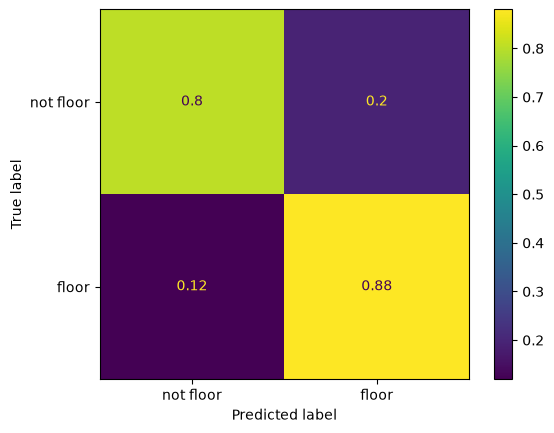

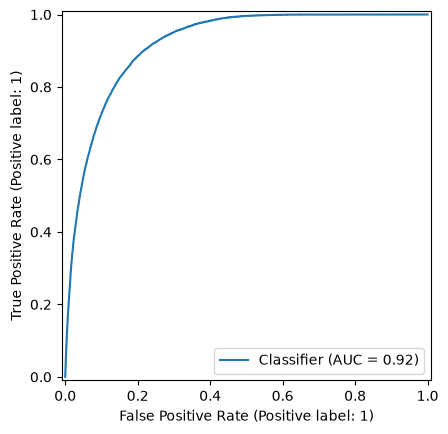

In [9]:
print(f"AUC:      {roc_auc_score(y_test, y_proba):.3f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}  (baseline 'always not floor': {1 - y_test.mean():.3f})")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", display_labels=["not floor", "floor"])
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.show()

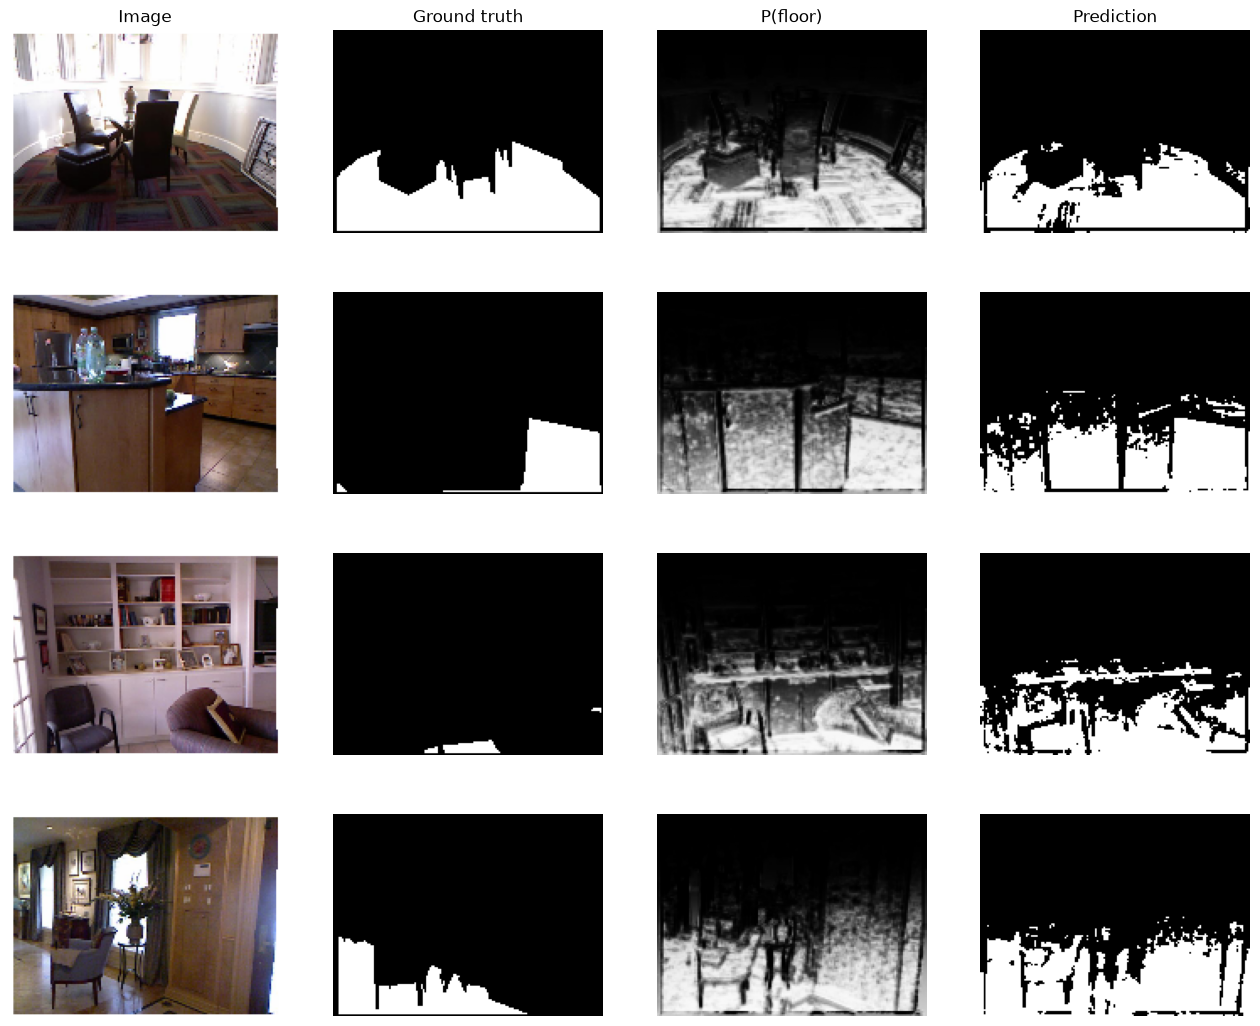

In [10]:
STRIDE = 4   # predict one pixel every 4 (faster)
p = PATCH_SIZE // 2

fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # Build one patch for each pixel on the grid
    padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode="edge")
    rows = range(0, image.shape[0], STRIDE)
    cols = range(0, image.shape[1], STRIDE)
    h, w = image.shape[:2]
    X = np.array([extract_patch(padded, r + p, c + p, PATCH_SIZE) for r in rows for c in cols])
    X = X.astype(np.float32) / 255.0
    pos = np.array([(r / (h - 1), c / (w - 1)) for r in rows for c in cols], dtype=np.float32)

    # Predict and put back into a (small) image
    proba = model.predict([X, pos], batch_size=2048, verbose=0).reshape(len(rows), len(cols))
    pred = proba > 0.5

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()